# EGFR/ERK $IC_{50}$ Analysis

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# Parameters

# Tissue depth range (cm)
L = 0.2
nx = 200

x = np.linspace(0, L, nx)
dx = x[1] - x[0]

# Diffusion simulation time (s)
T_diffusion = 3600
nt = 30000

dt = T_diffusion / nt

# Layer boundaries (cm)
boundary_1 = 0.05
boundary_2 = 0.12

# Diffusion coefficients (cm^2/s)
D1 = 5e-7
D2 = 1e-7
D3 = 5e-7

# Spatial diffusivity profile
D = np.full(nx, D1)

D[x >= boundary_1] = D2
D[x >= boundary_2] = D3

# Constant drug source at vessel boundary
C_source = 1.0

# Initial concentration
C = np.zeros(nx)

C[0] = C_source

# Save concentration profiles over time
save_every = 25
saved_profiles = []

# Initial state vector
y0 = [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]

# Parameter dictionary
params = {
    "EGF" : 1.0,
    "IC_50" : 0.3,
    "n" : 1.0,
    "k_EGF" : 1.0,
    "k_EGFR_off" : 0.5,
    "k_RAS" : 1.0,
    "k_RAS_off" : 0.5,
    "k_RAF" : 1.0,
    "k_RAF_off" : 0.5,
    "k_MEK" : 1.0,
    "k_MEK_off" : 0.5,
    "k_ERK" : 1.0,
    "k_ERK_off" : 0.5,
    "k_T" : 1.0,
    "k_deg" : 0.5,
    "k_P" : 1.0,
    "k_loss" : 0.5,
}

species = [
    "EGFR*",
    "RAS*",
    "RAF*",
    "MEK*",
    "ERK*",
    "Cyclin D",
    "P"
]

# Final solution array
solutions_final = np.zeros((7, nx))

# Steady-state run time
T_steady = 80
T_eval = np.linspace(0, T_steady, 500)

# Saving steady-state run time for sensitivity analysis
np.save("saved_parameters/exp04b_T_steady.npy", T_steady)

# ODE function definition
def pathway(t, y, params, G_x):
    # External factors
    EGF = params["EGF"]
    G = G_x
    IC_50 = params["IC_50"]
    n = params["n"]

    # Extract activated protein and Cyclin D/Proliferation rates from array y
    EGFR_star, RAS_star, RAF_star, MEK_star, ERK_star, CycD, P = y

    # Total protein concentrations
    EGFR_tot = 1.0
    RAS_tot = 1.0
    RAF_tot = 1.0
    MEK_tot = 1.0
    ERK_tot = 1.0

    # Rate constants (normalized currently)
    k_EGF = params["k_EGF"]
    k_EGFR_off = params["k_EGFR_off"]

    k_RAS = params["k_RAS"]
    k_RAS_off = params["k_RAS_off"]

    k_RAF = params["k_RAF"]
    k_RAF_off = params["k_RAF_off"]

    k_MEK = params["k_MEK"]
    k_MEK_off = params["k_MEK_off"]

    k_ERK = params["k_ERK"]
    k_ERK_off = params["k_ERK_off"]

    k_T = params["k_T"]
    k_deg = params["k_deg"]

    k_P = params["k_P"]
    k_loss = params["k_loss"]

    # Calculating derivatives
    EGFR_gefit = 1 / (1 + (G / IC_50) ** n)
    EGFR_act = k_EGF * EGF * (EGFR_tot - EGFR_star) * EGFR_gefit
    EGFR_dect = k_EGFR_off * EGFR_star

    dEGFR = EGFR_act - EGFR_dect

    RAS_act = k_RAS * EGFR_star * (RAS_tot - RAS_star)
    RAS_dect = k_RAS_off * RAS_star

    dRAS = RAS_act - RAS_dect

    RAF_act = k_RAF * RAS_star * (RAF_tot - RAF_star)
    RAF_dect = k_RAF_off * RAF_star

    dRAF = RAF_act - RAF_dect

    MEK_act = k_MEK * RAF_star * (MEK_tot - MEK_star)
    MEK_dect = k_MEK_off * MEK_star

    dMEK = MEK_act - MEK_dect

    ERK_act = k_ERK * MEK_star * (ERK_tot - ERK_star)
    ERK_dect = k_ERK_off * ERK_star

    dERK = ERK_act - ERK_dect

    CycD_act = k_T * ERK_star
    CycD_dect = k_deg * CycD

    dCycD = CycD_act - CycD_dect

    P_act = k_P * CycD
    P_dect = k_loss * P

    dP = P_act - P_dect

    return [dEGFR, dRAS, dRAF, 
                dMEK, dERK, dCycD, dP]

In [3]:
from scipy.optimize import brentq

def get_steady_state(G, params):

    solution = solve_ivp(
        pathway,
        [0, T_steady],
        y0,
        args=(params, G),
        rtol=1e-9,
        atol=1e-12
    )

    if not solution.success:
        raise RuntimeError(solution.message)

    return solution.y[:, -1]

def get_EGFR_response(G, p):
    ss = get_steady_state(G, p)
    return ss[0]


def get_ERK_response(G, p):
    ss = get_steady_state(G, p)
    return ss[4]


def calculate_EGFR_IC50_precise(p):

    # No-drug EGFR
    EGFR0 = get_EGFR_response(0.0, p)

    # Guard against invalid no-drug response
    if not np.isfinite(EGFR0) or EGFR0 <= 0:
        return np.nan

    def response_difference(logG):

        G = 10 ** logG
        EGFR = get_EGFR_response(G, p)

        # Guard against invalid model output
        if not np.isfinite(EGFR):
            return np.nan

        normalized = EGFR / EGFR0

        return normalized - 0.5

    # Search over 0.001 nM → 1e6 nM
    logG_low = -3
    logG_high = 6

    f_low = response_difference(logG_low)
    f_high = response_difference(logG_high)

    # Guard against invalid endpoint values
    if not np.isfinite(f_low) or not np.isfinite(f_high):
        return np.nan

    # If the response never crosses 50%, return NaN
    if f_low * f_high > 0:
        return np.nan

    root = brentq(
        response_difference,
        logG_low,
        logG_high
    )

    return 10 ** root


def calculate_ERK_IC50_precise(p):

    # No-drug ERK
    ERK0 = get_ERK_response(0.0, p)

    # Guard against invalid no-drug response
    if not np.isfinite(ERK0) or ERK0 <= 0:
        return np.nan

    def response_difference(logG):

        G = 10 ** logG
        ERK = get_ERK_response(G, p)

        # Guard against invalid model output
        if not np.isfinite(ERK):
            return np.nan

        normalized = ERK / ERK0

        return normalized - 0.5

    # Search over 0.001 nM → 1e6 nM
    logG_low = -3
    logG_high = 6

    f_low = response_difference(logG_low)
    f_high = response_difference(logG_high)

    # Guard against invalid endpoint values
    if not np.isfinite(f_low) or not np.isfinite(f_high):
        return np.nan

    # If the response never crosses 50%, return NaN
    if f_low * f_high > 0:
        return np.nan

    root = brentq(
        response_difference,
        logG_low,
        logG_high
    )

    return 10 ** root

In [6]:
EGFR_IC50 = calculate_EGFR_IC50_precise(params)
ERK_IC50 = calculate_ERK_IC50_precise(params)

print(f"Model EGFR IC50: {EGFR_IC50:.4f} nM")
print(f"Model ERK IC50:  {ERK_IC50:.4f} nM")

print(f"\nEGFR mismatch: {EGFR_IC50 / 15.9:.2f}x")
print(f"ERK mismatch:  {ERK_IC50 / 19.0:.2f}x")

Model EGFR IC50: 0.9000 nM
Model ERK IC50:  18.9000 nM

EGFR mismatch: 0.06x
ERK mismatch:  0.99x


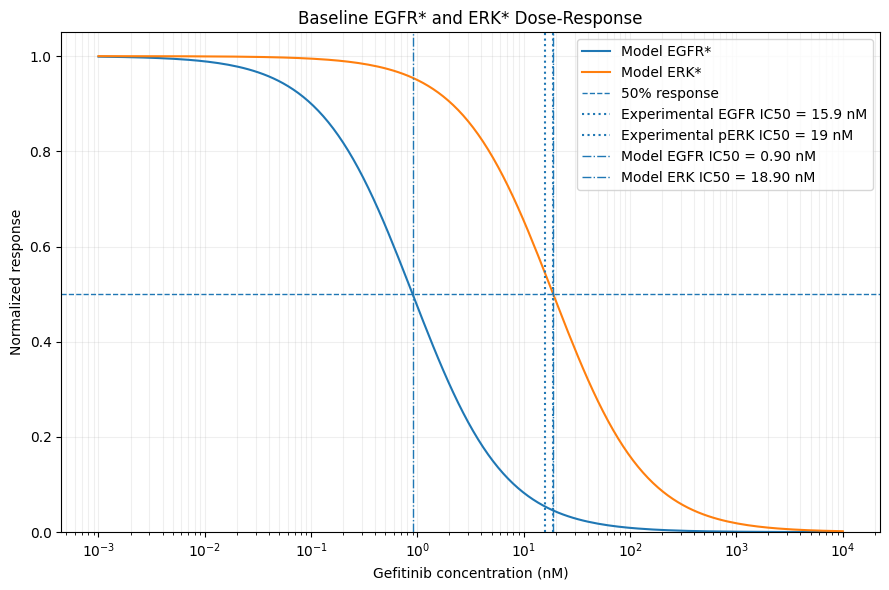

In [7]:
# ============================================
# BASELINE DOSE-RESPONSE CURVES
# ============================================

# Gefitinib concentration range (nM)
G_conc = np.logspace(-3, 4, 150)

# Calculate baseline responses
EGFR_response = np.array([
    get_EGFR_response(G, params)
    for G in G_conc
])

ERK_response = np.array([
    get_ERK_response(G, params)
    for G in G_conc
])

# Normalize to no-drug response
EGFR0 = get_EGFR_response(0.0, params)
ERK0 = get_ERK_response(0.0, params)

EGFR_normalized = EGFR_response / EGFR0
ERK_normalized = ERK_response / ERK0


# Calculate precise model IC50s
EGFR_IC50 = calculate_EGFR_IC50_precise(params)
ERK_IC50 = calculate_ERK_IC50_precise(params)


# ============================================
# PLOT
# ============================================

plt.figure(figsize=(9, 6))

plt.semilogx(
    G_conc,
    EGFR_normalized,
    label="Model EGFR*"
)

plt.semilogx(
    G_conc,
    ERK_normalized,
    label="Model ERK*"
)

# 50% response line
plt.axhline(
    0.5,
    linestyle="--",
    linewidth=1,
    label="50% response"
)

# Experimental IC50 reference lines
plt.axvline(
    15.9,
    linestyle=":",
    linewidth=1.5,
    label="Experimental EGFR IC50 = 15.9 nM"
)

plt.axvline(
    19.0,
    linestyle=":",
    linewidth=1.5,
    label="Experimental pERK IC50 = 19 nM"
)

# Model IC50 lines
plt.axvline(
    EGFR_IC50,
    linestyle="-.",
    linewidth=1,
    label=f"Model EGFR IC50 = {EGFR_IC50:.2f} nM"
)

plt.axvline(
    ERK_IC50,
    linestyle="-.",
    linewidth=1,
    label=f"Model ERK IC50 = {ERK_IC50:.2f} nM"
)


# Labels
plt.xlabel("Gefitinib concentration (nM)")
plt.ylabel("Normalized response")
plt.title("Baseline EGFR* and ERK* Dose-Response")

plt.ylim(0, 1.05)
plt.grid(True, which="both", alpha=0.2)
plt.legend()

plt.tight_layout()
plt.show()

In [10]:
IC50_shift = ERK_IC50 / EGFR_IC50

print(f"EGFR → ERK IC50 shift: {IC50_shift:.2f}x")

ERK_ratio = ERK_IC50 / 19.0

print(f"Model / experimental pERK IC50: {ERK_ratio:.2f}x")

EGFR_ratio = EGFR_IC50 / 15.9

print(f"Model / experimental EGFR IC50: {EGFR_ratio:.2f}x")

EGFR → ERK IC50 shift: 21.00x
Model / experimental pERK IC50: 0.99x
Model / experimental EGFR IC50: 0.06x


# Cascade Analysis

In [11]:
# ============================================
# CASCADE SENSITIVITY ANALYSIS
# ============================================

baseline_ratios = {
    "RAS": params["k_RAS"] / params["k_RAS_off"],
    "RAF": params["k_RAF"] / params["k_RAF_off"],
    "MEK": params["k_MEK"] / params["k_MEK_off"],
    "ERK": params["k_ERK"] / params["k_ERK_off"]
}

print("Baseline activation/deactivation ratios:")

for node, ratio in baseline_ratios.items():
    print(f"{node}: {ratio:.3f}")

Baseline activation/deactivation ratios:
RAS: 2.000
RAF: 2.000
MEK: 2.000
ERK: 2.000


In [13]:
# Relative changes from 0.1x to 10x baseline
ratio_multipliers = np.logspace(-1, 1, 15)

cascade_results = {
    "RAS": [],
    "RAF": [],
    "MEK": [],
    "ERK": []
}


for node in ["RAS", "RAF", "MEK", "ERK"]:

    for multiplier in ratio_multipliers:

        # Copy baseline parameters
        p_test = params.copy()

        # Desired activation/deactivation ratio
        desired_ratio = (
            baseline_ratios[node] * multiplier
        )

        # Keep deactivation rate fixed
        # and change activation rate
        if node == "RAS":
            p_test["k_RAS"] = (
                desired_ratio * p_test["k_RAS_off"]
            )

        elif node == "RAF":
            p_test["k_RAF"] = (
                desired_ratio * p_test["k_RAF_off"]
            )

        elif node == "MEK":
            p_test["k_MEK"] = (
                desired_ratio * p_test["k_MEK_off"]
            )

        elif node == "ERK":
            p_test["k_ERK"] = (
                desired_ratio * p_test["k_ERK_off"]
            )

        # Calculate ERK IC50
        ic50 = calculate_ERK_IC50_precise(p_test)

        cascade_results[node].append(ic50)

In [14]:
print("\nERK IC50 sensitivity:")

for node in ["RAS", "RAF", "MEK", "ERK"]:

    values = np.array(cascade_results[node])

    print(
        f"{node}: "
        f"{np.nanmin(values):.2f} → "
        f"{np.nanmax(values):.2f} nM"
    )


ERK IC50 sensitivity:
RAS: 2.70 → 180.90 nM
RAF: 3.78 → 170.10 nM
MEK: 5.94 → 148.50 nM
ERK: 10.26 → 105.30 nM


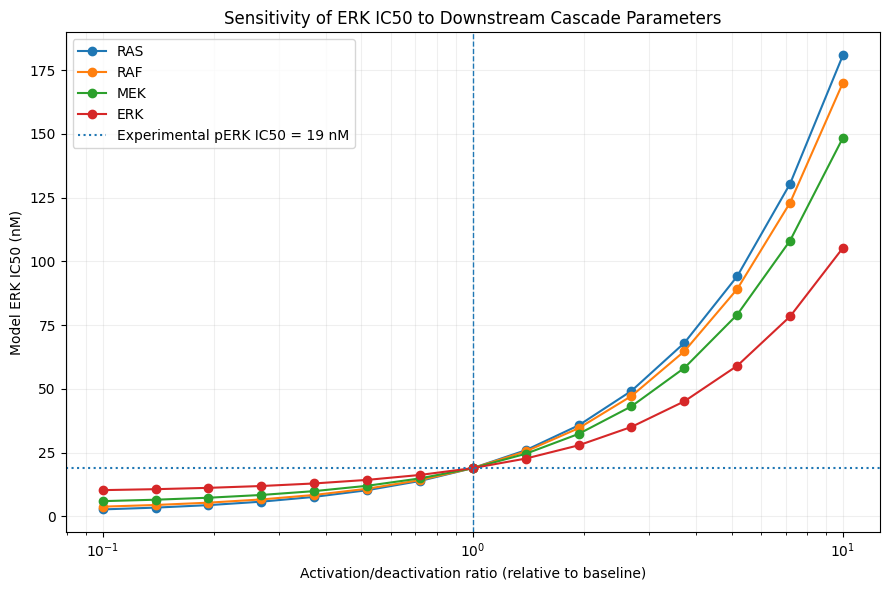

In [15]:
# ============================================
# PLOT CASCADE SENSITIVITY
# ============================================

plt.figure(figsize=(9, 6))

for node in ["RAS", "RAF", "MEK", "ERK"]:

    values = np.array(cascade_results[node])

    plt.semilogx(
        ratio_multipliers,
        values,
        marker="o",
        label=node
    )


# Baseline
plt.axvline(
    1,
    linestyle="--",
    linewidth=1
)

# Experimental pERK IC50
plt.axhline(
    19,
    linestyle=":",
    linewidth=1.5,
    label="Experimental pERK IC50 = 19 nM"
)

plt.xlabel(
    "Activation/deactivation ratio "
    "(relative to baseline)"
)

plt.ylabel("Model ERK IC50 (nM)")

plt.title(
    "Sensitivity of ERK IC50 to Downstream Cascade Parameters"
)

plt.grid(
    True,
    which="both",
    alpha=0.2
)

plt.legend()
plt.tight_layout()
plt.show()

In [16]:
# ============================================
# LOCAL LOG-SENSITIVITY
# ============================================

local_sensitivities = {}

for node in ["RAS", "RAF", "MEK", "ERK"]:

    values = np.array(cascade_results[node])

    # Find points closest to 0.5x and 2x baseline
    low_index = np.argmin(
        np.abs(ratio_multipliers - 0.5)
    )

    high_index = np.argmin(
        np.abs(ratio_multipliers - 2.0)
    )

    low_ic50 = values[low_index]
    high_ic50 = values[high_index]

    low_multiplier = ratio_multipliers[low_index]
    high_multiplier = ratio_multipliers[high_index]

    if (
        np.isfinite(low_ic50)
        and np.isfinite(high_ic50)
        and low_ic50 > 0
        and high_ic50 > 0
    ):

        S = (
            np.log(high_ic50) - np.log(low_ic50)
        ) / (
            np.log(high_multiplier)
            - np.log(low_multiplier)
        )

    else:
        S = np.nan

    local_sensitivities[node] = S


print("\nLocal log-sensitivities:")

for node, S in local_sensitivities.items():
    print(f"{node}: {S:.4f}")


Local log-sensitivities:
RAS: 0.9494
RAF: 0.8834
MEK: 0.7552
ERK: 0.5077


In [17]:
# ============================================
# IC50 THROUGH THE SIGNALING CASCADE
# ============================================

def get_node_response(G, p, node_index):
    ss = get_steady_state(G, p)
    return ss[node_index]


def calculate_node_IC50_precise(p, node_index):

    node0 = get_node_response(0.0, p, node_index)

    if not np.isfinite(node0) or node0 <= 0:
        return np.nan

    def response_difference(logG):

        G = 10 ** logG

        node = get_node_response(G, p, node_index)

        if not np.isfinite(node):
            return np.nan

        return node / node0 - 0.5

    logG_low = -3
    logG_high = 6

    f_low = response_difference(logG_low)
    f_high = response_difference(logG_high)

    if not np.isfinite(f_low) or not np.isfinite(f_high):
        return np.nan

    if f_low * f_high > 0:
        return np.nan

    root = brentq(
        response_difference,
        logG_low,
        logG_high
    )

    return 10 ** root


# Calculate IC50 for every signaling node

print("IC50 through signaling cascade:")
print("--------------------------------")

for i, node in enumerate(species):

    ic50 = calculate_node_IC50_precise(params, i)

    print(f"{node:10s}: {ic50:.4f} nM")

IC50 through signaling cascade:
--------------------------------
EGFR*     : 0.9000 nM
RAS*      : 2.1000 nM
RAF*      : 4.5000 nM
MEK*      : 9.3000 nM
ERK*      : 18.9000 nM
Cyclin D  : 18.9000 nM
P         : 18.9000 nM


In [18]:
# ============================================
# ROBUSTNESS OF CASCADE IC50 SHIFT
# ============================================

# Common activation/deactivation ratios to test
test_ratios = np.array([
    0.25,
    0.5,
    1.0,
    1.5,
    2.0,
    3.0,
    4.0,
    6.0,
    8.0
])

# Model EGFR IC50 does not depend on downstream ratios
EGFR_IC50_baseline = calculate_node_IC50_precise(
    params,
    0
)

robustness_results = []

for ratio in test_ratios:

    # Copy baseline parameters
    p_test = params.copy()

    # Keep all deactivation rates fixed
    # and change activation rates so that
    # k_act / k_off = ratio

    p_test["k_RAS"] = ratio * p_test["k_RAS_off"]
    p_test["k_RAF"] = ratio * p_test["k_RAF_off"]
    p_test["k_MEK"] = ratio * p_test["k_MEK_off"]
    p_test["k_ERK"] = ratio * p_test["k_ERK_off"]

    # Calculate ERK IC50
    ERK_IC50 = calculate_node_IC50_precise(
        p_test,
        4
    )

    # Calculate IC50 shift
    IC50_shift = ERK_IC50 / EGFR_IC50_baseline

    robustness_results.append([
        ratio,
        ERK_IC50,
        IC50_shift
    ])


robustness_results = np.array(robustness_results)


# ============================================
# PRINT RESULTS
# ============================================

print("Cascade robustness analysis")
print("--------------------------------")
print(
    f"Baseline EGFR IC50: "
    f"{EGFR_IC50_baseline:.4f} nM"
)

print()

print(
    f"{'Ratio':>8} "
    f"{'ERK IC50 (nM)':>16} "
    f"{'EGFR→ERK Shift':>18}"
)

for row in robustness_results:

    ratio = row[0]
    ERK_IC50 = row[1]
    shift = row[2]

    print(
        f"{ratio:8.2f} "
        f"{ERK_IC50:16.4f} "
        f"{shift:18.2f}x"
    )

Cascade robustness analysis
--------------------------------
Baseline EGFR IC50: 0.9000 nM

   Ratio    ERK IC50 (nM)     EGFR→ERK Shift
    0.25           1.0992               1.22x
    0.50           1.4625               1.63x
    1.00           3.3000               3.67x
    1.50           8.2125               9.13x
    2.00          18.9000              21.00x
    3.00          72.9000              81.00x
    4.00         204.9000             227.67x
    6.00         933.3000            1037.00x
    8.00        2808.9000            3121.00x


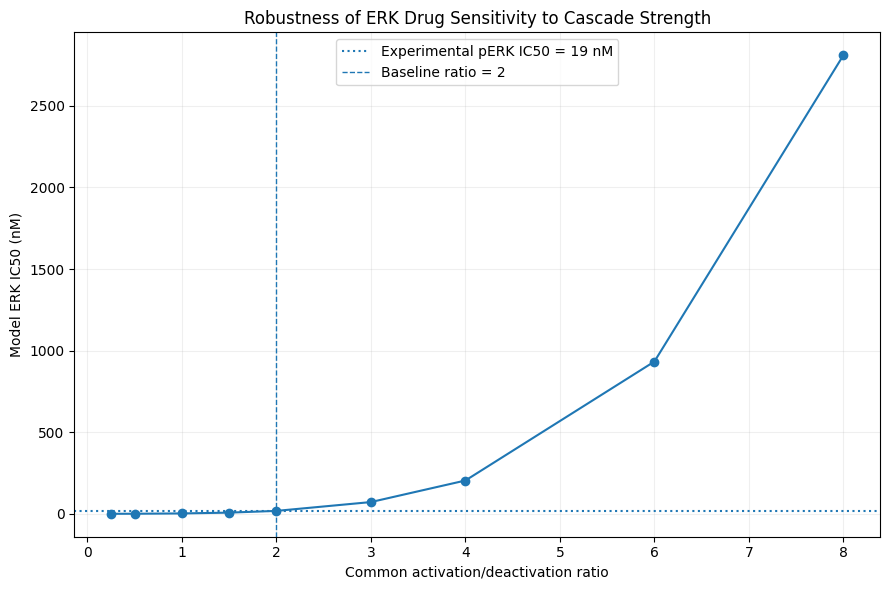

In [19]:
# ============================================
# ERK IC50 VS CASCADE STRENGTH
# ============================================

plt.figure(figsize=(9, 6))

plt.plot(
    robustness_results[:, 0],
    robustness_results[:, 1],
    marker="o"
)

plt.axhline(
    19.0,
    linestyle=":",
    linewidth=1.5,
    label="Experimental pERK IC50 = 19 nM"
)

plt.axvline(
    2.0,
    linestyle="--",
    linewidth=1,
    label="Baseline ratio = 2"
)

plt.xlabel(
    "Common activation/deactivation ratio"
)

plt.ylabel(
    "Model ERK IC50 (nM)"
)

plt.title(
    "Robustness of ERK Drug Sensitivity to Cascade Strength"
)

plt.grid(
    True,
    alpha=0.2
)

plt.legend()

plt.tight_layout()
plt.show()

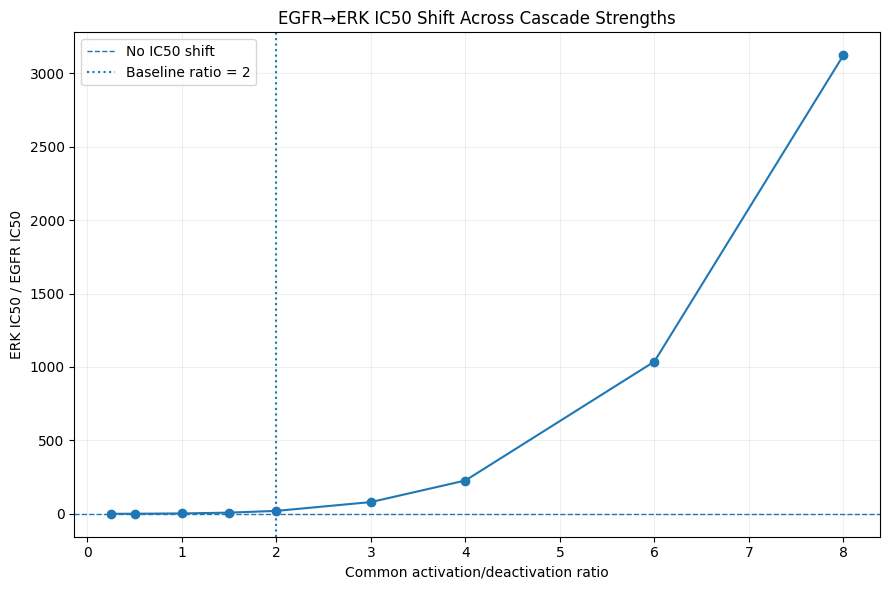

In [20]:
# ============================================
# EGFR → ERK IC50 SHIFT
# ============================================

plt.figure(figsize=(9, 6))

plt.plot(
    robustness_results[:, 0],
    robustness_results[:, 2],
    marker="o"
)

plt.axhline(
    1.0,
    linestyle="--",
    linewidth=1,
    label="No IC50 shift"
)

plt.axvline(
    2.0,
    linestyle=":",
    linewidth=1.5,
    label="Baseline ratio = 2"
)

plt.xlabel(
    "Common activation/deactivation ratio"
)

plt.ylabel(
    "ERK IC50 / EGFR IC50"
)

plt.title(
    "EGFR→ERK IC50 Shift Across Cascade Strengths"
)

plt.grid(
    True,
    alpha=0.2
)

plt.legend()

plt.tight_layout()
plt.show()

In [21]:
# ============================================
# ROBUSTNESS SUMMARY
# ============================================

shifts = robustness_results[:, 2]

min_shift = np.min(shifts)
max_shift = np.max(shifts)

baseline_index = np.argmin(
    np.abs(test_ratios - 2.0)
)

baseline_shift = shifts[baseline_index]

print("\nRobustness summary")
print("--------------------------------")

print(
    f"Minimum IC50 shift: "
    f"{min_shift:.2f}x"
)

print(
    f"Maximum IC50 shift: "
    f"{max_shift:.2f}x"
)

print(
    f"Baseline IC50 shift: "
    f"{baseline_shift:.2f}x"
)

print(
    f"Range across tested ratios: "
    f"{max_shift - min_shift:.2f}x"
)


Robustness summary
--------------------------------
Minimum IC50 shift: 1.22x
Maximum IC50 shift: 3121.00x
Baseline IC50 shift: 21.00x
Range across tested ratios: 3119.78x


In [24]:
from scipy.optimize import least_squares
from scipy.optimize import brentq

# ============================================
# FIT DRUG RESPONSE PARAMETERS
# ============================================

experimental_EGFR_IC50 = 15.9
experimental_ERK_IC50 = 19.0

def calculate_EGFR_IC50_precise(p):

    EGFR0 = get_steady_state(0.0, p)[0]

    def response_difference(logG):

        G = 10 ** logG

        EGFR = get_steady_state(G, p)[0]

        normalized = EGFR / EGFR0

        return normalized - 0.5

    logG_low = -3
    logG_high = 6

    f_low = response_difference(logG_low)
    f_high = response_difference(logG_high)

    if not np.isfinite(f_low) or not np.isfinite(f_high):
        return np.nan

    if f_low * f_high > 0:
        return np.nan

    root = brentq(
        response_difference,
        logG_low,
        logG_high
    )

    return 10 ** root

In [25]:
# ============================================
# FIT IC50 AND HILL COEFFICIENT
# ============================================

def drug_response_objective(log_params):

    # Fit in log-space so both parameters
    # remain positive.

    IC50 = 10 ** log_params[0]
    n = 10 ** log_params[1]

    p = params.copy()

    p["IC_50"] = IC50
    p["n"] = n

    model_EGFR_IC50 = calculate_EGFR_IC50_precise(p)
    model_ERK_IC50 = calculate_ERK_IC50_precise(p)

    if not np.isfinite(model_EGFR_IC50):
        return [1e6, 1e6]

    if not np.isfinite(model_ERK_IC50):
        return [1e6, 1e6]

    # Log residuals are useful because IC50
    # values are multiplicative quantities.

    residual_EGFR = np.log10(
        model_EGFR_IC50 / experimental_EGFR_IC50
    )

    residual_ERK = np.log10(
        model_ERK_IC50 / experimental_ERK_IC50
    )

    return [
        residual_EGFR,
        residual_ERK
    ]

In [26]:
# Initial guess:
# IC50 = 1 nM
# n = 1

initial_guess = np.log10([
    1.0,
    1.0
])

fit = least_squares(
    drug_response_objective,
    initial_guess,
    bounds=(
        np.log10([0.001, 0.1]),
        np.log10([1000, 100])
    )
)

best_IC50 = 10 ** fit.x[0]
best_n = 10 ** fit.x[1]

print("DRUG RESPONSE FIT")
print("--------------------------------")

print(
    f"Best Hill IC50 parameter: "
    f"{best_IC50:.4f} nM"
)

print(
    f"Best Hill coefficient n: "
    f"{best_n:.4f}"
)

DRUG RESPONSE FIT
--------------------------------
Best Hill IC50 parameter: 14.9102 nM
Best Hill coefficient n: 17.0925


In [27]:
# ============================================
# EVALUATE FIT
# ============================================

fitted_params = params.copy()

fitted_params["IC_50"] = best_IC50
fitted_params["n"] = best_n

fitted_EGFR_IC50 = calculate_EGFR_IC50_precise(
    fitted_params
)

fitted_ERK_IC50 = calculate_ERK_IC50_precise(
    fitted_params
)

print("\nFIT RESULTS")
print("--------------------------------")

print(
    f"EGFR IC50: "
    f"{fitted_EGFR_IC50:.4f} nM"
)

print(
    f"Experimental: "
    f"{experimental_EGFR_IC50:.4f} nM"
)

print()

print(
    f"ERK IC50: "
    f"{fitted_ERK_IC50:.4f} nM"
)

print(
    f"Experimental: "
    f"{experimental_ERK_IC50:.4f} nM"
)


FIT RESULTS
--------------------------------
EGFR IC50: 15.9000 nM
Experimental: 15.9000 nM

ERK IC50: 19.0000 nM
Experimental: 19.0000 nM


In [28]:
# ============================================
# EFFECT OF HILL COEFFICIENT ON IC50 SHIFT
# ============================================

n_values = np.logspace(-1, 2, 30)

hill_results = []

for n_test in n_values:

    p_test = params.copy()

    p_test["n"] = n_test

    # Keep the Hill IC50 fixed temporarily
    p_test["IC_50"] = 14.9102

    EGFR_ic50 = calculate_EGFR_IC50_precise(p_test)
    ERK_ic50 = calculate_ERK_IC50_precise(p_test)

    if np.isfinite(EGFR_ic50) and np.isfinite(ERK_ic50):

        shift = ERK_ic50 / EGFR_ic50

        hill_results.append([
            n_test,
            EGFR_ic50,
            ERK_ic50,
            shift
        ])

hill_results = np.array(hill_results)

print("Hill coefficient analysis")
print("--------------------------------")
print(
    f"{'n':>10} "
    f"{'EGFR IC50':>15} "
    f"{'ERK IC50':>15} "
    f"{'ERK/EGFR':>15}"
)

for row in hill_results:

    print(
        f"{row[0]:10.3f} "
        f"{row[1]:15.3f} "
        f"{row[2]:15.3f} "
        f"{row[3]:15.3f}"
    )

/var/folders/sj/6mw6cz_x1dg1nlhv9xgk5rgh0000gn/T/ipykernel_77313/2643226020.py:132: RuntimeWarning: overflow encountered in scalar power
  EGFR_gefit = 1 / (1 + (G / IC_50) ** n)


Hill coefficient analysis
--------------------------------
         n       EGFR IC50        ERK IC50        ERK/EGFR
     0.418         207.110      304054.883        1468.082
     0.530         118.576       37114.542         313.001
     0.672          76.407        7075.163          92.599
     0.853          54.040        1916.438          35.463
     1.083          41.133         684.671          16.645
     1.374          33.172         304.239           9.171
     1.743          28.001         160.551           5.734
     2.212          24.500          97.017           3.960
     2.807          22.052          65.231           2.958
     3.562          20.297          47.709           2.351
     4.520          19.012          37.285           1.961
     5.736          18.058          30.702           1.700
     7.279          17.339          26.344           1.519
     9.237          16.793          23.350           1.390
    11.721          16.375          21.232           1.2

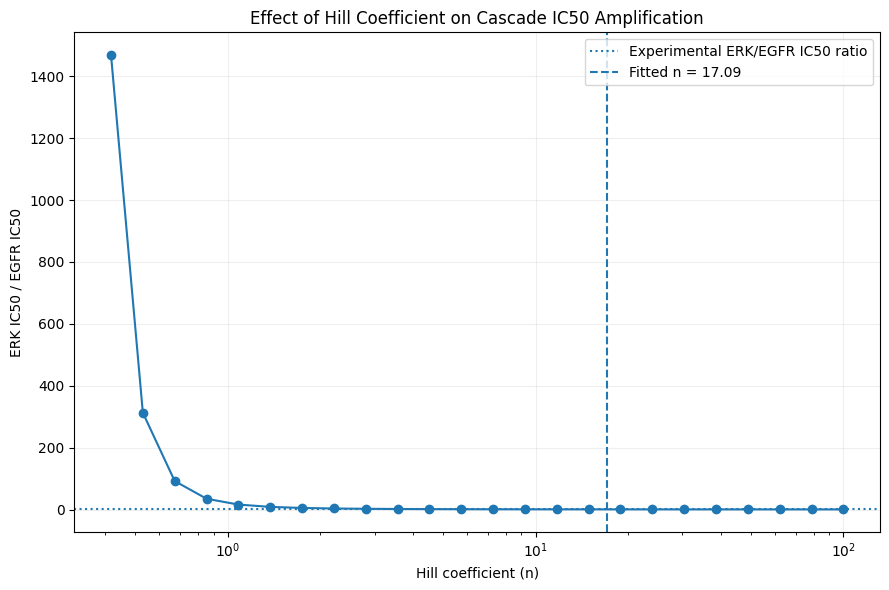

In [29]:
plt.figure(figsize=(9, 6))

plt.semilogx(
    hill_results[:, 0],
    hill_results[:, 3],
    marker="o"
)

plt.axhline(
    19.0 / 15.9,
    linestyle=":",
    linewidth=1.5,
    label="Experimental ERK/EGFR IC50 ratio"
)

plt.axvline(
    17.0925,
    linestyle="--",
    linewidth=1.5,
    label="Fitted n = 17.09"
)

plt.xlabel("Hill coefficient (n)")
plt.ylabel("ERK IC50 / EGFR IC50")
plt.title("Effect of Hill Coefficient on Cascade IC50 Amplification")

plt.grid(True, alpha=0.2)
plt.legend()
plt.tight_layout()
plt.show()

Experimental L858R EGFR IC50 values:
Y845: 13.0 nM
Y992: 18.0 nM
Y1045: 8.0 nM
Y1068: 54.0 nM
Y1148: 16.0 nM
Y1173: 10.0 nM

Geometric mean: 15.90 nM
Experimental pERK IC50: 19.0 nM

PHOSPHOSITE CONSTRAINT ANALYSIS
Site         Experimental EGFR         Model ERK     ERK / EGFR
-----------------------------------------------------------------
Y845                     13.00            273.00         21.00x
Y992                     18.00            378.00         21.00x
Y1045                     8.00            168.00         21.00x
Y1068                    54.00           1134.00         21.00x
Y1148                    16.00            336.00         21.00x
Y1173                    10.00            210.00         21.00x
-----------------------------------------------------------------
Geo mean                 15.90            333.96         21.00x

COMPARISON WITH EXPERIMENTAL pERK IC50
Y845: Model = 273.00 nM | Experiment = 19.00 nM | Ratio = 14.37x | Error = +1336.8%
Y992: Model = 378

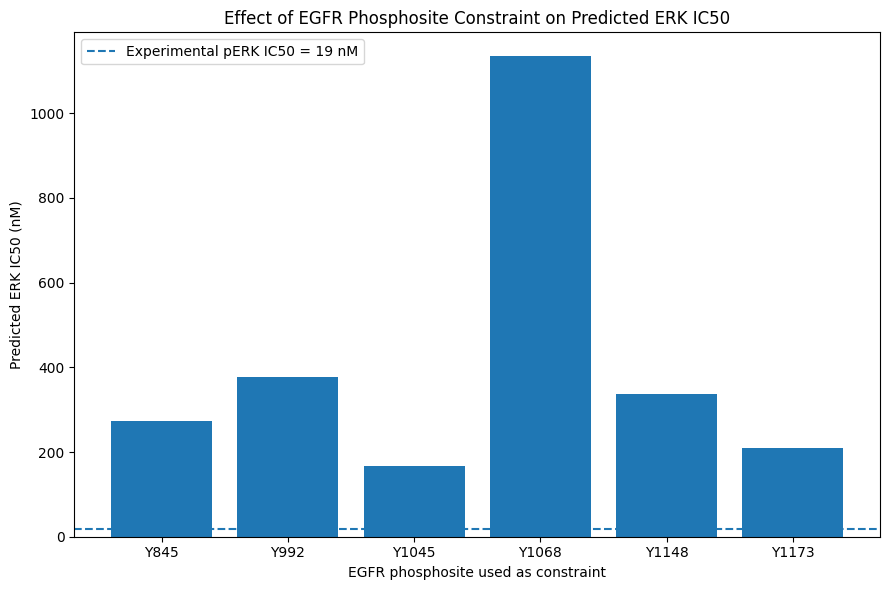

In [31]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import brentq

# ============================================================
# EXPERIMENTAL DATA — Kim et al. 2015
# ============================================================

tyrosine_residues = np.array([
    845, 992, 1045, 1068, 1148, 1173
])

# L858R gefitinib IC50 values in nM
EGFR_IC50_exp = np.array([
    13.0,
    18.0,
    8.0,
    54.0,
    16.0,
    10.0
])

pERK_IC50_exp = 19.0  # nM


# ============================================================
# MODEL PARAMETERS
# ============================================================

y0 = [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]

params = {
    "EGF": 1.0,

    # This will be changed for each experimental EGFR IC50
    "IC_50": 0.3,

    "n": 1.0,

    "k_EGF": 1.0,
    "k_EGFR_off": 0.5,

    "k_RAS": 1.0,
    "k_RAS_off": 0.5,

    "k_RAF": 1.0,
    "k_RAF_off": 0.5,

    "k_MEK": 1.0,
    "k_MEK_off": 0.5,

    "k_ERK": 1.0,
    "k_ERK_off": 0.5,

    "k_T": 1.0,
    "k_deg": 0.5,

    "k_P": 1.0,
    "k_loss": 0.5,
}

T_steady = 80


# ============================================================
# ODE MODEL
# ============================================================

def pathway(t, y, params, G_x):

    EGF = params["EGF"]
    G = G_x

    IC_50 = params["IC_50"]
    n = params["n"]

    EGFR_star, RAS_star, RAF_star, MEK_star, ERK_star, CycD, P = y

    # Total protein pools
    EGFR_tot = 1.0
    RAS_tot = 1.0
    RAF_tot = 1.0
    MEK_tot = 1.0
    ERK_tot = 1.0

    # Rate constants
    k_EGF = params["k_EGF"]
    k_EGFR_off = params["k_EGFR_off"]

    k_RAS = params["k_RAS"]
    k_RAS_off = params["k_RAS_off"]

    k_RAF = params["k_RAF"]
    k_RAF_off = params["k_RAF_off"]

    k_MEK = params["k_MEK"]
    k_MEK_off = params["k_MEK_off"]

    k_ERK = params["k_ERK"]
    k_ERK_off = params["k_ERK_off"]

    k_T = params["k_T"]
    k_deg = params["k_deg"]

    k_P = params["k_P"]
    k_loss = params["k_loss"]

    # --------------------------------------------------------
    # EGFR
    # --------------------------------------------------------

    EGFR_gefit = 1 / (1 + (G / IC_50) ** n)

    EGFR_act = (
        k_EGF
        * EGF
        * (EGFR_tot - EGFR_star)
        * EGFR_gefit
    )

    EGFR_deact = k_EGFR_off * EGFR_star

    dEGFR = EGFR_act - EGFR_deact

    # --------------------------------------------------------
    # RAS
    # --------------------------------------------------------

    RAS_act = (
        k_RAS
        * EGFR_star
        * (RAS_tot - RAS_star)
    )

    RAS_deact = k_RAS_off * RAS_star

    dRAS = RAS_act - RAS_deact

    # --------------------------------------------------------
    # RAF
    # --------------------------------------------------------

    RAF_act = (
        k_RAF
        * RAS_star
        * (RAF_tot - RAF_star)
    )

    RAF_deact = k_RAF_off * RAF_star

    dRAF = RAF_act - RAF_deact

    # --------------------------------------------------------
    # MEK
    # --------------------------------------------------------

    MEK_act = (
        k_MEK
        * RAF_star
        * (MEK_tot - MEK_star)
    )

    MEK_deact = k_MEK_off * MEK_star

    dMEK = MEK_act - MEK_deact

    # --------------------------------------------------------
    # ERK
    # --------------------------------------------------------

    ERK_act = (
        k_ERK
        * MEK_star
        * (ERK_tot - ERK_star)
    )

    ERK_deact = k_ERK_off * ERK_star

    dERK = ERK_act - ERK_deact

    # --------------------------------------------------------
    # Cyclin D
    # --------------------------------------------------------

    CycD_act = k_T * ERK_star
    CycD_deact = k_deg * CycD

    dCycD = CycD_act - CycD_deact

    # --------------------------------------------------------
    # Proliferation
    # --------------------------------------------------------

    P_act = k_P * CycD
    P_deact = k_loss * P

    dP = P_act - P_deact

    return [
        dEGFR,
        dRAS,
        dRAF,
        dMEK,
        dERK,
        dCycD,
        dP
    ]


# ============================================================
# STEADY STATE
# ============================================================

def get_steady_state(G, params):

    solution = solve_ivp(
        pathway,
        [0, T_steady],
        y0,
        args=(params, G),
        rtol=1e-9,
        atol=1e-12
    )

    if not solution.success:
        raise RuntimeError(solution.message)

    return solution.y[:, -1]


# ============================================================
# ERK RESPONSE
# ============================================================

def get_ERK_response(G, params):

    ss = get_steady_state(G, params)

    return ss[4]


# ============================================================
# CALCULATE MODEL ERK IC50
# ============================================================

def calculate_ERK_IC50(params):

    # No-drug ERK response
    ERK0 = get_ERK_response(0.0, params)

    def response_difference(logG):

        G = 10 ** logG

        ERK = get_ERK_response(G, params)

        normalized = ERK / ERK0

        return normalized - 0.5

    # Search from 0.001 nM to 1,000,000 nM
    logG_low = -3
    logG_high = 6

    f_low = response_difference(logG_low)
    f_high = response_difference(logG_high)

    if f_low * f_high > 0:

        return np.nan

    root = brentq(
        response_difference,
        logG_low,
        logG_high
    )

    return 10 ** root


# ============================================================
# GEOMETRIC MEAN
# ============================================================

geometric_mean_EGFR = np.exp(
    np.mean(np.log(EGFR_IC50_exp))
)

print("Experimental L858R EGFR IC50 values:")
for tyr, ic50 in zip(tyrosine_residues, EGFR_IC50_exp):
    print(f"Y{tyr}: {ic50:.1f} nM")

print()
print(f"Geometric mean: {geometric_mean_EGFR:.2f} nM")
print(f"Experimental pERK IC50: {pERK_IC50_exp:.1f} nM")


# ============================================================
# PHOSPHOSITE CONSTRAINT ANALYSIS
# ============================================================

# Experimental L858R EGFR phosphosite IC50s (nM)
tyrosine_residues = np.array([
    845, 992, 1045, 1068, 1148, 1173
])

EGFR_IC50_exp = np.array([
    13.0,
    18.0,
    8.0,
    54.0,
    16.0,
    10.0
])

experimental_pERK_IC50 = 19.0


# ============================================================
# CALIBRATE MODEL PARAMETER TO EXPERIMENTAL EGFR IC50
# ============================================================

# For the current model with n = 1:
#
# Model EGFR IC50 = 3 * params["IC_50"]
#
# Therefore:
#
# params["IC_50"] = experimental EGFR IC50 / 3

model_ERK_IC50 = []

for experimental_EGFR_IC50 in EGFR_IC50_exp:

    params["n"] = 1.0

    # IMPORTANT:
    # This is the model parameter, NOT the model EGFR IC50.
    params["IC_50"] = experimental_EGFR_IC50 / 3.0

    # Calculate the resulting ERK IC50
    ERK_IC50 = calculate_ERK_IC50(params)

    model_ERK_IC50.append(ERK_IC50)


model_ERK_IC50 = np.array(model_ERK_IC50)


# ============================================================
# GEOMETRIC MEAN CONSTRAINT
# ============================================================

geometric_mean_EGFR = np.exp(
    np.mean(np.log(EGFR_IC50_exp))
)

params["IC_50"] = geometric_mean_EGFR / 3.0

ERK_IC50_geomean = calculate_ERK_IC50(params)


# ============================================================
# PRINT RESULTS
# ============================================================

print("\n" + "=" * 65)
print("PHOSPHOSITE CONSTRAINT ANALYSIS")
print("=" * 65)

print(
    f"{'Site':<10}"
    f"{'Experimental EGFR':>20}"
    f"{'Model ERK':>18}"
    f"{'ERK / EGFR':>15}"
)

print("-" * 65)

for tyr, egfr_ic50, erk_ic50 in zip(
    tyrosine_residues,
    EGFR_IC50_exp,
    model_ERK_IC50
):

    ratio = erk_ic50 / egfr_ic50

    print(
        f"Y{tyr:<9}"
        f"{egfr_ic50:>20.2f}"
        f"{erk_ic50:>18.2f}"
        f"{ratio:>14.2f}x"
    )

print("-" * 65)

print(
    f"{'Geo mean':<10}"
    f"{geometric_mean_EGFR:>20.2f}"
    f"{ERK_IC50_geomean:>18.2f}"
    f"{ERK_IC50_geomean / geometric_mean_EGFR:>14.2f}x"
)


# ============================================================
# COMPARISON WITH EXPERIMENTAL pERK
# ============================================================

print("\n" + "=" * 65)
print("COMPARISON WITH EXPERIMENTAL pERK IC50")
print("=" * 65)

for tyr, model_ic50 in zip(
    tyrosine_residues,
    model_ERK_IC50
):

    experimental_ratio = model_ic50 / experimental_pERK_IC50

    percent_error = (
        (model_ic50 - experimental_pERK_IC50)
        / experimental_pERK_IC50
        * 100
    )

    print(
        f"Y{tyr}: "
        f"Model = {model_ic50:.2f} nM | "
        f"Experiment = {experimental_pERK_IC50:.2f} nM | "
        f"Ratio = {experimental_ratio:.2f}x | "
        f"Error = {percent_error:+.1f}%"
    )


# ============================================================
# PLOT
# ============================================================

plt.figure(figsize=(9, 6))

plt.bar(
    [f"Y{tyr}" for tyr in tyrosine_residues],
    model_ERK_IC50
)

plt.axhline(
    experimental_pERK_IC50,
    linestyle="--",
    label="Experimental pERK IC50 = 19 nM"
)

plt.xlabel("EGFR phosphosite used as constraint")
plt.ylabel("Predicted ERK IC50 (nM)")
plt.title(
    "Effect of EGFR Phosphosite Constraint on Predicted ERK IC50"
)

plt.legend()
plt.tight_layout()
plt.show()

**Finding:** When constrained by each of six experimentally measured L858R EGFR phosphosite IC₅₀ values (8–54 nM), the model consistently predicted substantially higher downstream ERK IC₅₀ values (168–1134 nM) than the experimentally reported pERK IC₅₀ of 19 ± 9 nM. The predicted ERK/EGFR IC₅₀ ratio remained 21-fold across all phosphosite constraints, indicating that the discrepancy is primarily a structural property of the current cascade formulation rather than a consequence of selecting a particular EGFR phosphosite. Using the geometric-mean EGFR IC₅₀ of 15.9 nM produced a predicted ERK IC₅₀ of 334 nM, approximately 17.6-fold above the experimental pERK IC₅₀.

In [32]:
import numpy as np
import matplotlib.pyplot as plt

# -----------------------------
# Tissue / diffusion parameters
# -----------------------------

L = 0.2          # cm
nx = 200
dx = L / (nx - 1)

D1 = 5e-7        # cm^2/s
D2 = 1e-7        # cm^2/s
D3 = 5e-7        # cm^2/s

C_source = 1.0

# Interfaces
interface_1 = 0.05   # cm
interface_2 = 0.12   # cm

x = np.linspace(0, L, nx)

# -----------------------------
# Spatially varying D(x)
# -----------------------------

D = np.zeros(nx)

D[x < interface_1] = D1
D[(x >= interface_1) & (x < interface_2)] = D2
D[x >= interface_2] = D3

# -----------------------------
# Simulation parameters
# -----------------------------

T_diffusion = 8 * 3600       # 8 hours in seconds

# Keep your previous stable timestep
dt = 0.12

nt = int(T_diffusion / dt)

print(f"dx = {dx:.6e} cm")
print(f"dt = {dt:.6e} s")
print(f"nt = {nt}")

# -----------------------------
# Experimental comparison times
# -----------------------------

validation_hours = np.array([0.5, 1.0, 4.0, 8.0])
validation_times = validation_hours * 3600

# Find which simulation timestep corresponds to each time
validation_indices = np.round(validation_times / dt).astype(int)

# -----------------------------
# Initial concentration
# -----------------------------

C = np.zeros(nx)

# Store concentration profiles here
saved_profiles = {}

# Save initial condition if useful
saved_profiles[0.0] = C.copy()

# -----------------------------
# Diffusion simulation
# -----------------------------

for n in range(nt + 1):

    # Save requested profiles
    if n in validation_indices:
        time_hours = (n * dt) / 3600
        saved_profiles[time_hours] = C.copy()

    # Don't update after final timestep
    if n == nt:
        break

    # ---------------------------------
    # Harmonic mean at cell interfaces
    # ---------------------------------

    D_interface = (
        2 * D[:-1] * D[1:]
        / (D[:-1] + D[1:])
    )

    # ---------------------------------
    # Calculate fluxes
    #
    # J = -D dC/dx
    # ---------------------------------

    J = -D_interface * np.diff(C) / dx

    # ---------------------------------
    # Update concentration
    #
    # dC/dt = -dJ/dx
    # ---------------------------------

    C_new = C.copy()

    # Interior points
    C_new[1:-1] = (
        C[1:-1]
        - (dt / dx) * (J[1:] - J[:-1])
    )

    # ---------------------------------
    # Boundary conditions
    # ---------------------------------

    # Constant concentration at exposed surface
    C_new[0] = C_source

    # No-flux at deepest boundary
    C_new[-1] = C_new[-2]

    C = C_new

# -----------------------------
# Print validation profiles
# -----------------------------

print("\nSaved validation profiles:")

for t in validation_hours:
    # Find closest saved key
    key = min(saved_profiles.keys(), key=lambda k: abs(k - t))
    profile = saved_profiles[key]

    print(
        f"{key:.1f} h: "
        f"surface = {profile[0]:.6f}, "
        f"center = {profile[-1]:.6f}, "
        f"R1/R4 = {profile[0] / profile[-1]:.6f}"
    )

dx = 1.005025e-03 cm
dt = 1.200000e-01 s
nt = 240000

Saved validation profiles:
0.5 h: surface = 1.000000, center = 0.000000, R1/R4 = 35143650721.422241
1.0 h: surface = 1.000000, center = 0.000003, R1/R4 = 319318.398228
4.0 h: surface = 1.000000, center = 0.028310, R1/R4 = 35.323103
8.0 h: surface = 1.000000, center = 0.147750, R1/R4 = 6.768210


In [33]:
# ---------------------------------
# Experimental data from Figure S2A
# Approximate digitized values
# ---------------------------------

experimental_R1 = np.array([
    4100,
    3900,
    2700,
    2100
])

experimental_R4 = np.array([
    3200,
    2800,
    2300,
    1700
])

experimental_ratio = experimental_R1 / experimental_R4


# ---------------------------------
# Model R1/R4
# ---------------------------------

model_ratio = []

for t in validation_hours:
    key = min(saved_profiles.keys(), key=lambda k: abs(k - t))
    profile = saved_profiles[key]

    R1_model = profile[0]
    R4_model = profile[-1]

    model_ratio.append(R1_model / R4_model)

model_ratio = np.array(model_ratio)


# ---------------------------------
# Relative error
# ---------------------------------

relative_error = (
    np.abs(model_ratio - experimental_ratio)
    / experimental_ratio
    * 100
)


# ---------------------------------
# Validation table
# ---------------------------------

print("\nDiffusion validation")
print("-" * 65)
print(
    f"{'Time (h)':>10}"
    f"{'Exp R1/R4':>15}"
    f"{'Model R1/R4':>17}"
    f"{'Error (%)':>15}"
)

for i, t in enumerate(validation_hours):
    print(
        f"{t:>10.1f}"
        f"{experimental_ratio[i]:>15.3f}"
        f"{model_ratio[i]:>17.3f}"
        f"{relative_error[i]:>15.2f}"
    )


Diffusion validation
-----------------------------------------------------------------
  Time (h)      Exp R1/R4      Model R1/R4      Error (%)
       0.5          1.281  35143650721.4222742919080596.37
       1.0          1.393       319318.398    22925323.46
       4.0          1.174           35.323        2909.01
       8.0          1.235            6.768         447.90


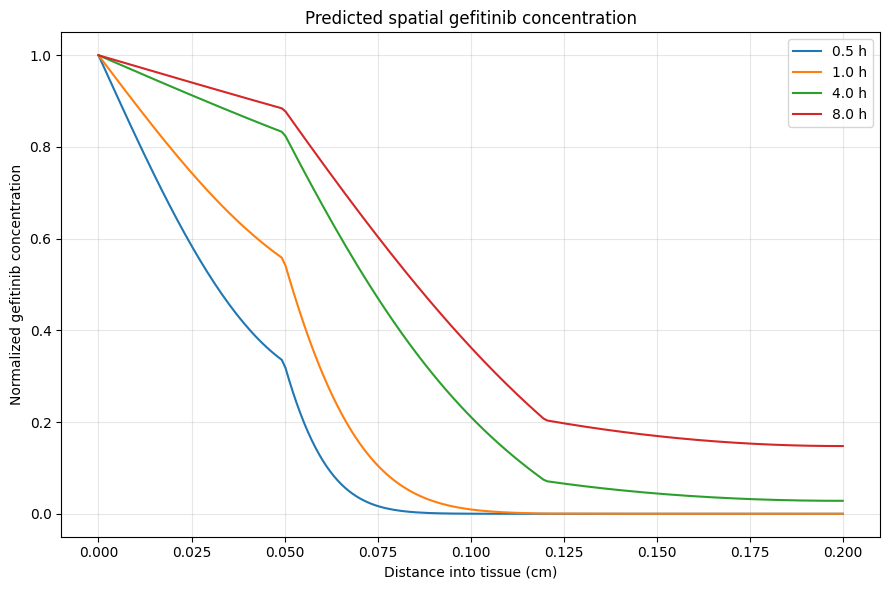

In [34]:
# ---------------------------------
# Plot spatial concentration profiles
# ---------------------------------

plt.figure(figsize=(9, 6))

for t in validation_hours:
    key = min(saved_profiles.keys(), key=lambda k: abs(k - t))
    profile = saved_profiles[key]

    plt.plot(
        x,
        profile,
        label=f"{key:.1f} h"
    )

plt.xlabel("Distance into tissue (cm)")
plt.ylabel("Normalized gefitinib concentration")
plt.title("Predicted spatial gefitinib concentration")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [35]:
# ---------------------------------
# Inspect model concentrations
# ---------------------------------

print("\nModel spatial concentrations")
print("-" * 75)
print(
    f"{'Time (h)':>10}"
    f"{'R1 (surface)':>20}"
    f"{'R4 (center)':>20}"
    f"{'R1/R4':>20}"
)

for t in validation_hours:

    key = min(saved_profiles.keys(), key=lambda k: abs(k - t))
    profile = saved_profiles[key]

    R1 = profile[0]
    R4 = profile[-1]

    ratio = R1 / R4 if R4 > 0 else np.inf

    print(
        f"{key:>10.1f}"
        f"{R1:>20.8e}"
        f"{R4:>20.8e}"
        f"{ratio:>20.4e}"
    )


Model spatial concentrations
---------------------------------------------------------------------------
  Time (h)        R1 (surface)         R4 (center)               R1/R4
       0.5      1.00000000e+00      2.84546420e-11          3.5144e+10
       1.0      1.00000000e+00      3.13167048e-06          3.1932e+05
       4.0      1.00000000e+00      2.83100838e-02          3.5323e+01
       8.0      1.00000000e+00      1.47749556e-01          6.7682e+00


In [36]:
# ---------------------------------
# Numerical sanity checks
# ---------------------------------

print("\nNumerical sanity checks")
print("-" * 50)

for t in validation_hours:

    key = min(saved_profiles.keys(), key=lambda k: abs(k - t))
    profile = saved_profiles[key]

    print(
        f"{key:.1f} h:"
        f"  min = {np.min(profile):.6e},"
        f"  max = {np.max(profile):.6e},"
        f"  negative values = {np.sum(profile < 0)},"
        f"  NaN = {np.sum(np.isnan(profile))}"
    )


Numerical sanity checks
--------------------------------------------------
0.5 h:  min = 2.845464e-11,  max = 1.000000e+00,  negative values = 0,  NaN = 0
1.0 h:  min = 3.131670e-06,  max = 1.000000e+00,  negative values = 0,  NaN = 0
4.0 h:  min = 2.831008e-02,  max = 1.000000e+00,  negative values = 0,  NaN = 0
8.0 h:  min = 1.477496e-01,  max = 1.000000e+00,  negative values = 0,  NaN = 0


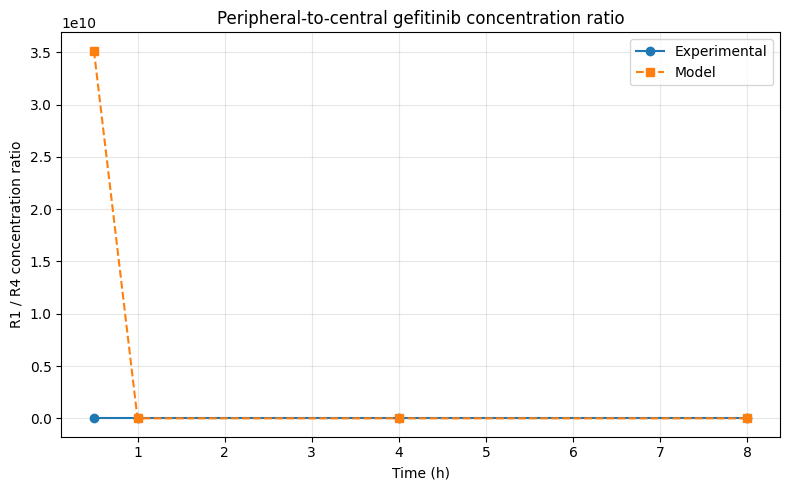

In [37]:
# ---------------------------------
# Experimental vs model R1/R4
# ---------------------------------

experimental_R1 = np.array([
    4100,
    3900,
    2700,
    2100
])

experimental_R4 = np.array([
    3200,
    2800,
    2300,
    1700
])

experimental_ratio = experimental_R1 / experimental_R4

model_ratio = []

for t in validation_hours:

    key = min(saved_profiles.keys(), key=lambda k: abs(k - t))
    profile = saved_profiles[key]

    R1 = profile[0]
    R4 = profile[-1]

    model_ratio.append(R1 / R4)

model_ratio = np.array(model_ratio)


# ---------------------------------
# Plot ratio comparison
# ---------------------------------

plt.figure(figsize=(8, 5))

plt.plot(
    validation_hours,
    experimental_ratio,
    "o-",
    label="Experimental"
)

plt.plot(
    validation_hours,
    model_ratio,
    "s--",
    label="Model"
)

plt.xlabel("Time (h)")
plt.ylabel("R1 / R4 concentration ratio")
plt.title("Peripheral-to-central gefitinib concentration ratio")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

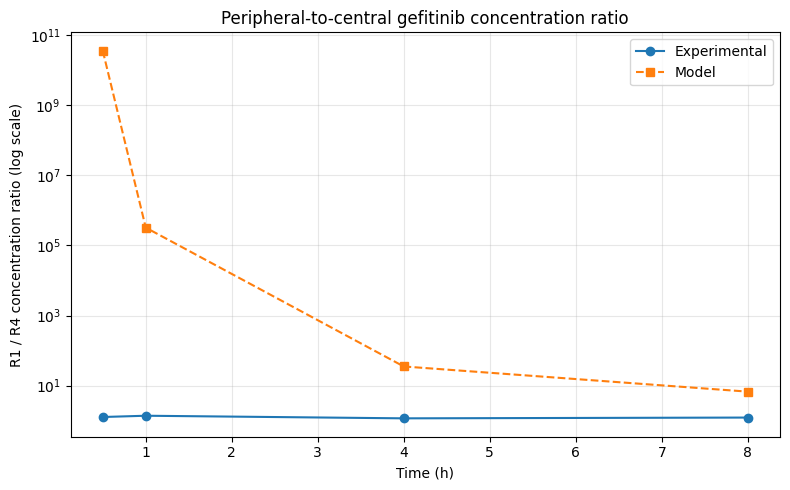

In [38]:
plt.figure(figsize=(8, 5))

plt.semilogy(
    validation_hours,
    experimental_ratio,
    "o-",
    label="Experimental"
)

plt.semilogy(
    validation_hours,
    model_ratio,
    "s--",
    label="Model"
)

plt.xlabel("Time (h)")
plt.ylabel("R1 / R4 concentration ratio (log scale)")
plt.title("Peripheral-to-central gefitinib concentration ratio")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [43]:
# ---------------------------------
# Experimental tumor PK
# ---------------------------------

experimental_times_h = np.array([
    0.5,
    1.0,
    4.0,
    8.0
])

experimental_R1 = np.array([
    4100,
    3900,
    2700,
    2100
])

experimental_R4 = np.array([
    3200,
    2800,
    2300,
    1700
])

# Normalize to the 0.5 h R1 concentration
R1_normalized = experimental_R1 / experimental_R1[0]
R4_normalized = experimental_R4 / experimental_R1[0]


# ---------------------------------
# Time-dependent boundary function
# ---------------------------------

boundary_times = np.array([
    0.0,
    0.5,
    1.0,
    4.0,
    8.0
])

boundary_values = np.array([
    0.0,                  # ASSUMPTION: no drug at t=0
    R1_normalized[0],
    R1_normalized[1],
    R1_normalized[2],
    R1_normalized[3]
])


def boundary_concentration(time_seconds):

    time_hours = time_seconds / 3600

    return np.interp(
        time_hours,
        boundary_times,
        boundary_values
    )


# ---------------------------------
# Simulation parameters
# ---------------------------------

T_diffusion = 8 * 3600
dt = 0.12
nt = int(T_diffusion / dt)

C = np.zeros(nx)

saved_profiles = {}

validation_times = experimental_times_h * 3600


# ---------------------------------
# Diffusion simulation
# ---------------------------------

for n in range(nt + 1):

    current_time = n * dt
    current_time_h = current_time / 3600

    # Save profile at experimental times
    for target_time in experimental_times_h:

        if abs(current_time_h - target_time) < dt / 3600:

            saved_profiles[target_time] = C.copy()

    if n == nt:
        break

    # ---------------------------------
    # Time-dependent boundary
    # ---------------------------------

    boundary = boundary_concentration(current_time)

    # ---------------------------------
    # Harmonic interface diffusivity
    # ---------------------------------

    D_interface = (
        2 * D[:-1] * D[1:]
        / (D[:-1] + D[1:])
    )

    # ---------------------------------
    # Flux
    # ---------------------------------

    J = -D_interface * np.diff(C) / dx

    # ---------------------------------
    # Update concentration
    # ---------------------------------

    C_new = C.copy()

    C_new[1:-1] = (
        C[1:-1]
        - (dt / dx) * (J[1:] - J[:-1])
    )

    # ---------------------------------
    # Boundary conditions
    # ---------------------------------

    C_new[0] = boundary

    # No-flux at deepest edge
    C_new[-1] = C_new[-2]

    C = C_new


# ---------------------------------
# Compare R4
# ---------------------------------

model_R4 = []

for t in experimental_times_h:

    profile = saved_profiles[t]

    model_R4.append(profile[-1])

model_R4 = np.array(model_R4)


print("\nR4 validation")
print("-" * 75)

print(
    f"{'Time (h)':>10}"
    f"{'Experimental R4':>20}"
    f"{'Model R4':>20}"
    f"{'Relative Error (%)':>22}"
)

for i, t in enumerate(experimental_times_h):

    error = (
        abs(model_R4[i] - R4_normalized[i])
        / R4_normalized[i]
        * 100
    )

    print(
        f"{t:>10.1f}"
        f"{R4_normalized[i]:>20.4f}"
        f"{model_R4[i]:>20.4f}"
        f"{error:>22.2f}"
    )


R4 validation
---------------------------------------------------------------------------
  Time (h)     Experimental R4            Model R4    Relative Error (%)
       0.5              0.7805              0.0000                100.00
       1.0              0.6829              0.0000                100.00
       4.0              0.5610              0.0218                 96.11
       8.0              0.4146              0.1124                 72.89


In [45]:
# ============================================
# D-SCALING SENSITIVITY / VALIDATION SWEEP
# ============================================

D_scales = np.array([
    3,
    4,
    5,
    6,
    7,
    8,
    9,
    10
])

# Experimental normalized R4
experimental_R4 = np.array([
    0.7805,
    0.6829,
    0.5610,
    0.4146
])

experimental_times_h = np.array([
    0.5,
    1.0,
    4.0,
    8.0
])

experimental_times_s = experimental_times_h * 3600

# Normalized experimental R1 used as boundary
experimental_R1 = np.array([
    4100,
    3900,
    2700,
    2100
])

R1_normalized = experimental_R1 / experimental_R1[0]

boundary_times_h = np.array([
    0.0,
    0.5,
    1.0,
    4.0,
    8.0
])

boundary_values = np.array([
    0.0,
    R1_normalized[0],
    R1_normalized[1],
    R1_normalized[2],
    R1_normalized[3]
])


def boundary_concentration(t_seconds):

    t_hours = t_seconds / 3600

    return np.interp(
        t_hours,
        boundary_times_h,
        boundary_values
    )


# --------------------------------------------
# Simulation function
# --------------------------------------------

def run_diffusion(D_scale):

    # -----------------------------------------
    # Scale diffusion coefficients
    # -----------------------------------------

    D1_test = D1 * D_scale
    D2_test = D2 * D_scale
    D3_test = D3 * D_scale

    # Construct D(x)
    D_test = np.zeros(nx)

    D_test[x < interface_1] = D1_test

    D_test[
        (x >= interface_1) &
        (x < interface_2)
    ] = D2_test

    D_test[x >= interface_2] = D3_test

    # -----------------------------------------
    # Stability-limited timestep
    # -----------------------------------------

    D_max = np.max(D_test)

    dt_stable = dx**2 / (2 * D_max)

    # Safety factor
    dt = 0.8 * dt_stable

    T_diffusion = 8 * 3600

    nt = int(np.ceil(T_diffusion / dt))

    # Recalculate dt so simulation ends exactly
    # at 8 hours
    dt = T_diffusion / nt

    print(
        f"D scale = {D_scale:.2f} | "
        f"dt = {dt:.5f} s | "
        f"nt = {nt}"
    )

    # -----------------------------------------
    # Initial concentration
    # -----------------------------------------

    C = np.zeros(nx)

    saved_profiles = {}

    # -----------------------------------------
    # Simulation
    # -----------------------------------------

    for n in range(nt + 1):

        current_time = n * dt
        current_time_h = current_time / 3600

        # -------------------------------------
        # Save nearest experimental times
        # -------------------------------------

        for target_h in experimental_times_h:

            target_s = target_h * 3600

            if abs(current_time - target_s) < dt:

                saved_profiles[target_h] = C.copy()

        if n == nt:
            break

        # -------------------------------------
        # Boundary concentration
        # -------------------------------------

        boundary = boundary_concentration(current_time)

        # -------------------------------------
        # Harmonic interface diffusivity
        # -------------------------------------

        D_interface = (
            2 * D_test[:-1] * D_test[1:]
            / (D_test[:-1] + D_test[1:])
        )

        # -------------------------------------
        # Flux
        # -------------------------------------

        J = (
            -D_interface
            * np.diff(C)
            / dx
        )

        # -------------------------------------
        # Explicit update
        # -------------------------------------

        C_new = C.copy()

        C_new[1:-1] = (
            C[1:-1]
            - (dt / dx)
            * (J[1:] - J[:-1])
        )

        # -------------------------------------
        # Boundary conditions
        # -------------------------------------

        C_new[0] = boundary

        # No flux at center/deep boundary
        C_new[-1] = C_new[-2]

        C = C_new

    # -----------------------------------------
    # Extract R4
    # -----------------------------------------

    model_R4 = []

    for t in experimental_times_h:

        if t not in saved_profiles:
            raise RuntimeError(
                f"Could not save profile at {t} h"
            )

        model_R4.append(
            saved_profiles[t][-1]
        )

    return np.array(model_R4)


# ============================================
# Run sweep
# ============================================

results = []

for scale in D_scales:

    model_R4 = run_diffusion(scale)

    errors = (
        np.abs(model_R4 - experimental_R4)
        / experimental_R4
        * 100
    )

    RMSE = np.sqrt(
        np.mean(
            (model_R4 - experimental_R4) ** 2
        )
    )

    results.append({
        "D_scale": scale,
        "R4_0.5h": model_R4[0],
        "R4_1h": model_R4[1],
        "R4_4h": model_R4[2],
        "R4_8h": model_R4[3],
        "RMSE": RMSE,
        "mean_error_percent": np.mean(errors)
    })


# ============================================
# Print results
# ============================================

print("\nD-scaling sensitivity")
print("-" * 100)

print(
    f"{'D scale':>10}"
    f"{'0.5 h':>12}"
    f"{'1 h':>12}"
    f"{'4 h':>12}"
    f"{'8 h':>12}"
    f"{'RMSE':>12}"
    f"{'Mean error':>15}"
)

for r in results:

    print(
        f"{r['D_scale']:>10.2f}"
        f"{r['R4_0.5h']:>12.4f}"
        f"{r['R4_1h']:>12.4f}"
        f"{r['R4_4h']:>12.4f}"
        f"{r['R4_8h']:>12.4f}"
        f"{r['RMSE']:>12.4f}"
        f"{r['mean_error_percent']:>14.2f}%"
    )

D scale = 3.00 | dt = 0.26935 s | nt = 106923
D scale = 4.00 | dt = 0.20201 s | nt = 142564
D scale = 5.00 | dt = 0.16161 s | nt = 178205
D scale = 6.00 | dt = 0.13468 s | nt = 213846
D scale = 7.00 | dt = 0.11544 s | nt = 249487
D scale = 8.00 | dt = 0.10101 s | nt = 285128
D scale = 9.00 | dt = 0.08978 s | nt = 320769
D scale = 10.00 | dt = 0.08081 s | nt = 356409

D-scaling sensitivity
----------------------------------------------------------------------------------------------------
   D scale       0.5 h         1 h         4 h         8 h        RMSE     Mean error
      3.00      0.0000      0.0033      0.2221      0.3826      0.5447         66.91%
      4.00      0.0002      0.0115      0.3094      0.4575      0.5303         63.37%
      5.00      0.0006      0.0249      0.3830      0.5080      0.5200         62.63%
      6.00      0.0017      0.0425      0.4448      0.5415      0.5114         61.22%
      7.00      0.0034      0.0628      0.4969      0.5630      0.5036       

In [46]:
results = []

for scale in D_scales:

    model_R4 = run_diffusion(scale)

    residuals = model_R4 - experimental_R4

    RMSE = np.sqrt(
        np.mean(residuals**2)
    )

    normalized_RMSE = (
        RMSE
        / np.mean(experimental_R4)
    )

    relative_errors = (
        np.abs(residuals)
        / experimental_R4
        * 100
    )

    results.append({
        "D_scale": scale,
        "R4_0.5h": model_R4[0],
        "R4_1h": model_R4[1],
        "R4_4h": model_R4[2],
        "R4_8h": model_R4[3],
        "RMSE": RMSE,
        "NRMSE": normalized_RMSE,
        "mean_error_percent": np.mean(relative_errors)
    })


print("\nD-scaling sensitivity")
print("-" * 110)

print(
    f"{'D scale':>10}"
    f"{'0.5 h':>12}"
    f"{'1 h':>12}"
    f"{'4 h':>12}"
    f"{'8 h':>12}"
    f"{'RMSE':>12}"
    f"{'NRMSE':>12}"
    f"{'Mean error':>15}"
)

for r in results:

    print(
        f"{r['D_scale']:>10.2f}"
        f"{r['R4_0.5h']:>12.4f}"
        f"{r['R4_1h']:>12.4f}"
        f"{r['R4_4h']:>12.4f}"
        f"{r['R4_8h']:>12.4f}"
        f"{r['RMSE']:>12.4f}"
        f"{r['NRMSE']:>12.4f}"
        f"{r['mean_error_percent']:>14.2f}%"
    )

D scale = 3.00 | dt = 0.26935 s | nt = 106923
D scale = 4.00 | dt = 0.20201 s | nt = 142564
D scale = 5.00 | dt = 0.16161 s | nt = 178205
D scale = 6.00 | dt = 0.13468 s | nt = 213846
D scale = 7.00 | dt = 0.11544 s | nt = 249487
D scale = 8.00 | dt = 0.10101 s | nt = 285128
D scale = 9.00 | dt = 0.08978 s | nt = 320769
D scale = 10.00 | dt = 0.08081 s | nt = 356409

D-scaling sensitivity
--------------------------------------------------------------------------------------------------------------
   D scale       0.5 h         1 h         4 h         8 h        RMSE       NRMSE     Mean error
      3.00      0.0000      0.0033      0.2221      0.3826      0.5447      0.8933         66.91%
      4.00      0.0002      0.0115      0.3094      0.4575      0.5303      0.8697         63.37%
      5.00      0.0006      0.0249      0.3830      0.5080      0.5200      0.8528         62.63%
      6.00      0.0017      0.0425      0.4448      0.5415      0.5114      0.8388         61.22%
      7

In [ ]:
# ============================================
# Plot model R4 vs D scaling
# ============================================

plt.figure(figsize=(9, 6))

for i, t in enumerate(experimental_times_h):

    model_values = [
        r[f"R4_{str(t).replace('.0', '')}h"]
        for r in results
    ]

    plt.plot(
        D_scales,
        model_values,
        "o-",
        label=f"Model R4 at {t:g} h"
    )

    plt.axhline(
        experimental_R4[i],
        linestyle="--",
        label=f"Experimental R4 at {t:g} h"
    )

plt.xscale("log")

plt.xlabel("Diffusion coefficient scaling factor")
plt.ylabel("Normalized R4 concentration")
plt.title("Effect of diffusion coefficient on central tumor concentration")
plt.legend()

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()